<a href="https://colab.research.google.com/github/MagimaaSree2007/silver-rover-terrain-detection/blob/main/Silver_Rover_Terrain_Control.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Silver Rover - Terrain Detection and Adaptive Motor Control

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Silver Rover project initialized successfully!")

Silver Rover project initialized successfully!


In [ ]:

import numpy as np
import pandas as pd

np.random.seed(42)

samples_per_terrain = 300
records = []

terrain_conditions = [
    "Flat",
    "Slope",
    "Rough",
    "Side_Slope",
    "High_Tilt"
]

for terrain in terrain_conditions:

    for i in range(samples_per_terrain):

        # Simulated pitch and roll angles in degrees
        if terrain == "Flat":
            pitch = np.random.normal(0, 1.5)
            roll = np.random.normal(0, 1.5)
            vibration = abs(np.random.normal(0.15, 0.05))
            impact = 0

        elif terrain == "Slope":
            pitch = np.random.normal(14, 2)
            roll = np.random.normal(0, 2)
            vibration = abs(np.random.normal(0.25, 0.06))
            impact = 0

        elif terrain == "Rough":
            pitch = np.random.normal(2, 3)
            roll = np.random.normal(1, 3)
            vibration = abs(np.random.normal(1.0, 0.2))
            impact = np.random.choice([0, 1], p=[0.7, 0.3])

        elif terrain == "Side_Slope":
            pitch = np.random.normal(1, 2)
            roll = np.random.normal(12, 2)
            vibration = abs(np.random.normal(0.25, 0.06))
            impact = 0

        else:  # High_Tilt
            pitch = np.random.choice([-1, 1]) * np.random.normal(30, 3)
            roll = np.random.normal(0, 3)
            vibration = abs(np.random.normal(0.4, 0.1))
            impact = 0

        # Simulated accelerometer readings in m/s^2
        ax = 9.81 * np.sin(np.radians(pitch))
        ay = 9.81 * np.sin(np.radians(roll))
        az = 9.81 * np.cos(np.radians(pitch)) * np.cos(
            np.radians(roll)
        )

        # Add measurement noise
        ax += np.random.normal(0, 0.15)
        ay += np.random.normal(0, 0.15)
        az += np.random.normal(0, 0.15)

        # Simulated gyroscope readings in degrees per second
        gx = np.random.normal(0, 2)
        gy = np.random.normal(0, 2)
        gz = np.random.normal(0, 2)

        records.append({
            "ax": ax,
            "ay": ay,
            "az": az,
            "gx": gx,
            "gy": gy,
            "gz": gz,
            "pitch": pitch,
            "roll": roll,
            "vibration_rms": vibration,
            "impact": impact,
            "actual_terrain": terrain
        })

df = pd.DataFrame(records)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset created successfully!
Dataset shape: (1500, 11)


,ax,ay,az,gx,gy,gz,pitch,roll,vibration_rms,impact,actual_terrain
0,0.356020,-0.070633,9.773986,3.158426,1.534869,-0.938949,0.745071,-0.207396,0.182384,0,Flat
1,0.175633,-0.406006,9.549551,-1.124575,-2.025662,0.628495,0.813840,-0.695127,0.126714,0,Flat
2,-0.267048,-0.352503,9.586813,-1.088765,0.221845,-2.301987,-1.362036,-2.118456,0.223282,0,Flat
3,0.006231,0.123589,9.806288,-2.115422,1.645090,-2.441687,0.563547,-0.900958,0.135415,0,Flat
4,0.083170,-0.392302,9.822651,-0.231297,-0.602207,-2.957044,0.313295,-2.939505,0.083591,0,Flat


In [ ]:

def detect_terrain(pitch, roll, vibration_rms):

    # Detect a potentially unsafe tilt first
    if abs(pitch) >= 25 or abs(roll) >= 20:
        return "High_Tilt"

    # Detect rough terrain using vibration
    elif vibration_rms >= 0.65:
        return "Rough"

    # Detect an uphill or downhill slope
    elif abs(pitch) >= 8:
        return "Slope"

    # Detect a sideways slope
    elif abs(roll) >= 8:
        return "Side_Slope"

    else:
        return "Flat"


df["predicted_terrain"] = df.apply(
    lambda row: detect_terrain(
        row["pitch"],
        row["roll"],
        row["vibration_rms"]
    ),
    axis=1
)

print("Terrain detection completed!")
display(df[[
    "pitch",
    "roll",
    "vibration_rms",
    "actual_terrain",
    "predicted_terrain"
]].head(10))


Terrain detection completed!


,pitch,roll,vibration_rms,actual_terrain,predicted_terrain
0,0.745071,-0.207396,0.182384,Flat,Flat
1,0.813840,-0.695127,0.126714,Flat,Flat
2,-1.362036,-2.118456,0.223282,Flat,Flat
3,0.563547,-0.900958,0.135415,Flat,Flat
4,0.313295,-2.939505,0.083591,Flat,Flat
5,-1.079766,-0.690958,0.202856,Flat,Flat
6,1.546499,1.396920,0.108039,Flat,Flat
7,-1.794310,1.218789,0.217812,Flat,Flat
8,-0.053739,2.346965,0.019013,Flat,Flat
9,0.535669,2.216841,0.124086,Flat,Flat


Terrain Detection Accuracy: 97.60%

Classification Report:
              precision    recall  f1-score   support

        Flat       0.93      1.00      0.97       300
   High_Tilt       1.00      0.95      0.98       300
       Rough       1.00      0.95      0.98       300
  Side_Slope       1.00      0.98      0.99       300
       Slope       0.95      0.99      0.97       300

    accuracy                           0.98      1500
   macro avg       0.98      0.98      0.98      1500
weighted avg       0.98      0.98      0.98      1500



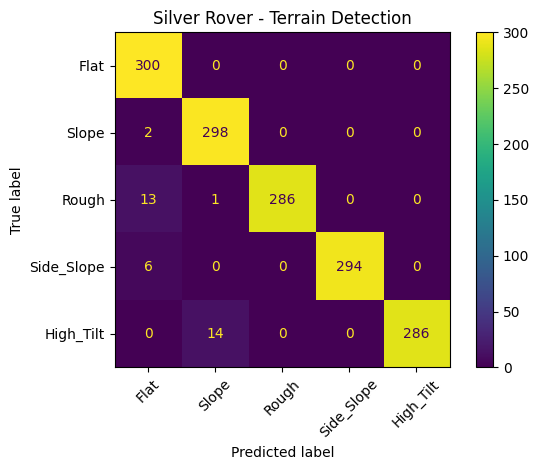

In [ ]:

y_true = df["actual_terrain"]
y_pred = df["predicted_terrain"]

accuracy = accuracy_score(y_true, y_pred)

print(f"Terrain Detection Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=terrain_conditions
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=terrain_conditions
)

display_matrix.plot(xticks_rotation=45)
plt.title("Silver Rover - Terrain Detection")
plt.tight_layout()
plt.show()


In [ ]:

def adaptive_motor_control(terrain, base_speed=150):

    # Keep the requested speed within the PWM command range
    base_speed = max(0, min(255, base_speed))

    if terrain == "Flat":
        speed_factor = 1.00

    elif terrain in ["Slope", "Side_Slope"]:
        speed_factor = 0.65

    elif terrain == "Rough":
        speed_factor = 0.40

    elif terrain == "High_Tilt":
        speed_factor = 0.00

    else:
        # Unknown terrain: fail safe in this simulation
        speed_factor = 0.00

    motor_speed = int(base_speed * speed_factor)

    return {
        "front_left": motor_speed,
        "front_right": motor_speed,
        "rear_left": motor_speed,
        "rear_right": motor_speed
    }


# Test the motor controller on each terrain
for terrain in terrain_conditions:

    commands = adaptive_motor_control(terrain)

    print(f"\nTerrain: {terrain}")
    print(commands)



Terrain: Flat
{'front_left': 150, 'front_right': 150, 'rear_left': 150, 'rear_right': 150}

Terrain: Slope
{'front_left': 97, 'front_right': 97, 'rear_left': 97, 'rear_right': 97}

Terrain: Rough
{'front_left': 60, 'front_right': 60, 'rear_left': 60, 'rear_right': 60}

Terrain: Side_Slope
{'front_left': 97, 'front_right': 97, 'rear_left': 97, 'rear_right': 97}

Terrain: High_Tilt
{'front_left': 0, 'front_right': 0, 'rear_left': 0, 'rear_right': 0}


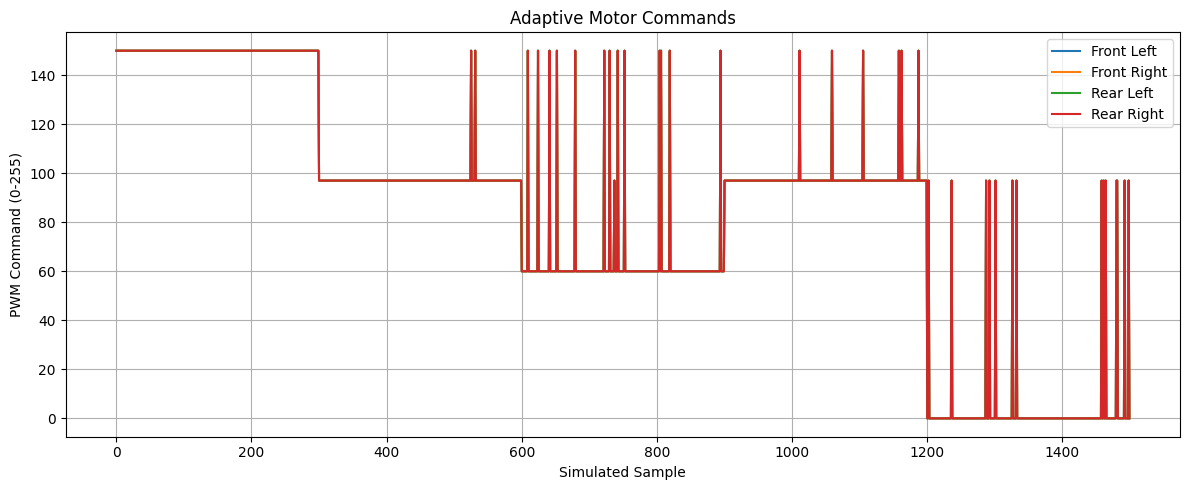

In [ ]:

motor_results = df["predicted_terrain"].apply(
    lambda terrain: adaptive_motor_control(terrain)
)

motor_df = pd.DataFrame(motor_results.tolist())

df["motor_front_left"] = motor_df["front_left"]
df["motor_front_right"] = motor_df["front_right"]
df["motor_rear_left"] = motor_df["rear_left"]
df["motor_rear_right"] = motor_df["rear_right"]

plt.figure(figsize=(12, 5))

plt.plot(df.index, df["motor_front_left"], label="Front Left")
plt.plot(df.index, df["motor_front_right"], label="Front Right")
plt.plot(df.index, df["motor_rear_left"], label="Rear Left")
plt.plot(df.index, df["motor_rear_right"], label="Rear Right")

plt.title("Adaptive Motor Commands")
plt.xlabel("Simulated Sample")
plt.ylabel("PWM Command (0-255)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

output_file = "silver_rover_simulated_dataset.csv"

df.to_csv(output_file, index=False)

print("Dataset saved:", output_file)
print("\nTerrain distribution:")
print(df["actual_terrain"].value_counts())

print("\nPrediction distribution:")
print(df["predicted_terrain"].value_counts())

from google.colab import files
files.download(output_file)


Dataset saved: silver_rover_simulated_dataset.csv

Terrain distribution:
actual_terrain
Flat          300
Slope         300
Rough         300
Side_Slope    300
High_Tilt     300
Name: count, dtype: int64

Prediction distribution:
predicted_terrain
Flat          321
Slope         313
Side_Slope    294
Rough         286
High_Tilt     286
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(7)

# Each terrain lasts 20 seconds at 10 samples per second
samples_per_terrain = 200
sample_rate = 10
records = []

terrain_order = [
    "Flat", "Slope", "Rough", "Side_Slope", "High_Tilt"
]

for terrain in terrain_order:
    for i in range(samples_per_terrain):

        # Simulate sensor values for each terrain
        if terrain == "Flat":
            pitch = np.random.normal(0, 1.5)
            roll = np.random.normal(0, 1.5)
            vibration = abs(np.random.normal(0.15, 0.05))

        elif terrain == "Slope":
            pitch = np.random.normal(14, 2)
            roll = np.random.normal(0, 2)
            vibration = abs(np.random.normal(0.25, 0.06))

        elif terrain == "Rough":
            pitch = np.random.normal(2, 3)
            roll = np.random.normal(1, 3)
            vibration = abs(np.random.normal(1.0, 0.2))

        elif terrain == "Side_Slope":
            pitch = np.random.normal(1, 2)
            roll = np.random.normal(12, 2)
            vibration = abs(np.random.normal(0.25, 0.06))

        else:
            pitch = np.random.choice([-1, 1]) * np.random.normal(30, 3)
            roll = np.random.normal(0, 3)
            vibration = abs(np.random.normal(0.4, 0.1))

        records.append({
            "time_s": len(records) / sample_rate,
            "pitch": pitch,
            "roll": roll,
            "vibration_rms": vibration,
            "actual_terrain": terrain
        })

stream_df = pd.DataFrame(records)

# Simulate a temporary sensor communication failure
stream_df["sensor_ok"] = True
stream_df.loc[450:459, "sensor_ok"] = False

# Detect terrain and calculate motor commands
predictions = []
motor_commands = []

for _, row in stream_df.iterrows():

    if not row["sensor_ok"]:
        # Fail-safe response to a detected sensor failure
        terrain = "Sensor_Fault"
        commands = {
            "front_left": 0,
            "front_right": 0,
            "rear_left": 0,
            "rear_right": 0
        }

    else:
        terrain = detect_terrain(
            row["pitch"],
            row["roll"],
            row["vibration_rms"]
        )

        commands = adaptive_motor_control(terrain)

    predictions.append(terrain)
    motor_commands.append(commands)

stream_df["predicted_terrain"] = predictions

motor_df = pd.DataFrame(motor_commands)
stream_df = pd.concat(
    [stream_df, motor_df],
    axis=1
)

print("Time-based simulation completed!")
print("Total simulated duration:",
      stream_df["time_s"].iloc[-1], "seconds")
print("Simulated sensor-fault samples:",
      (~stream_df["sensor_ok"]).sum())

display(stream_df.iloc[195:205])
display(stream_df.iloc[445:465])

Time-based simulation completed!
Total simulated duration: 99.9 seconds
Simulated sensor-fault samples: 10


,time_s,pitch,roll,vibration_rms,actual_terrain,sensor_ok,predicted_terrain,front_left,front_right,rear_left,rear_right
195,19.5,0.452317,-0.832685,0.208663,Flat,True,Flat,150,150,150,150
196,19.6,2.480924,0.872939,0.148787,Flat,True,Flat,150,150,150,150
197,19.7,1.621461,-0.556672,0.188227,Flat,True,Flat,150,150,150,150
198,19.8,-1.067376,-1.455549,0.178322,Flat,True,Flat,150,150,150,150
199,19.9,0.506895,2.856460,0.135995,Flat,True,Flat,150,150,150,150
200,20.0,14.046895,-2.279879,0.137843,Slope,True,Slope,97,97,97,97
201,20.1,10.438370,0.926216,0.179402,Slope,True,Slope,97,97,97,97
202,20.2,16.253574,2.844534,0.232876,Slope,True,Slope,97,97,97,97
203,20.3,17.316850,0.454399,0.317497,Slope,True,Slope,97,97,97,97
204,20.4,13.548587,1.918342,0.193401,Slope,True,Slope,97,97,97,97


,time_s,pitch,roll,vibration_rms,actual_terrain,sensor_ok,predicted_terrain,front_left,front_right,rear_left,rear_right
445,44.5,6.904251,-1.194757,0.933060,Rough,True,Rough,60,60,60,60
446,44.6,-0.861555,-2.492220,1.241244,Rough,True,Rough,60,60,60,60
447,44.7,3.892042,2.348883,1.115931,Rough,True,Rough,60,60,60,60
448,44.8,5.063946,5.531089,0.998561,Rough,True,Rough,60,60,60,60
449,44.9,0.977471,-2.071453,1.216461,Rough,True,Rough,60,60,60,60
450,45.0,0.455114,-3.483812,0.946241,Rough,False,Sensor_Fault,0,0,0,0
451,45.1,2.073028,3.497524,1.200749,Rough,False,Sensor_Fault,0,0,0,0
452,45.2,-0.193000,-1.400646,0.934373,Rough,False,Sensor_Fault,0,0,0,0
453,45.3,-1.634257,0.670920,1.092239,Rough,False,Sensor_Fault,0,0,0,0
454,45.4,2.128777,-3.840008,0.761586,Rough,False,Sensor_Fault,0,0,0,0


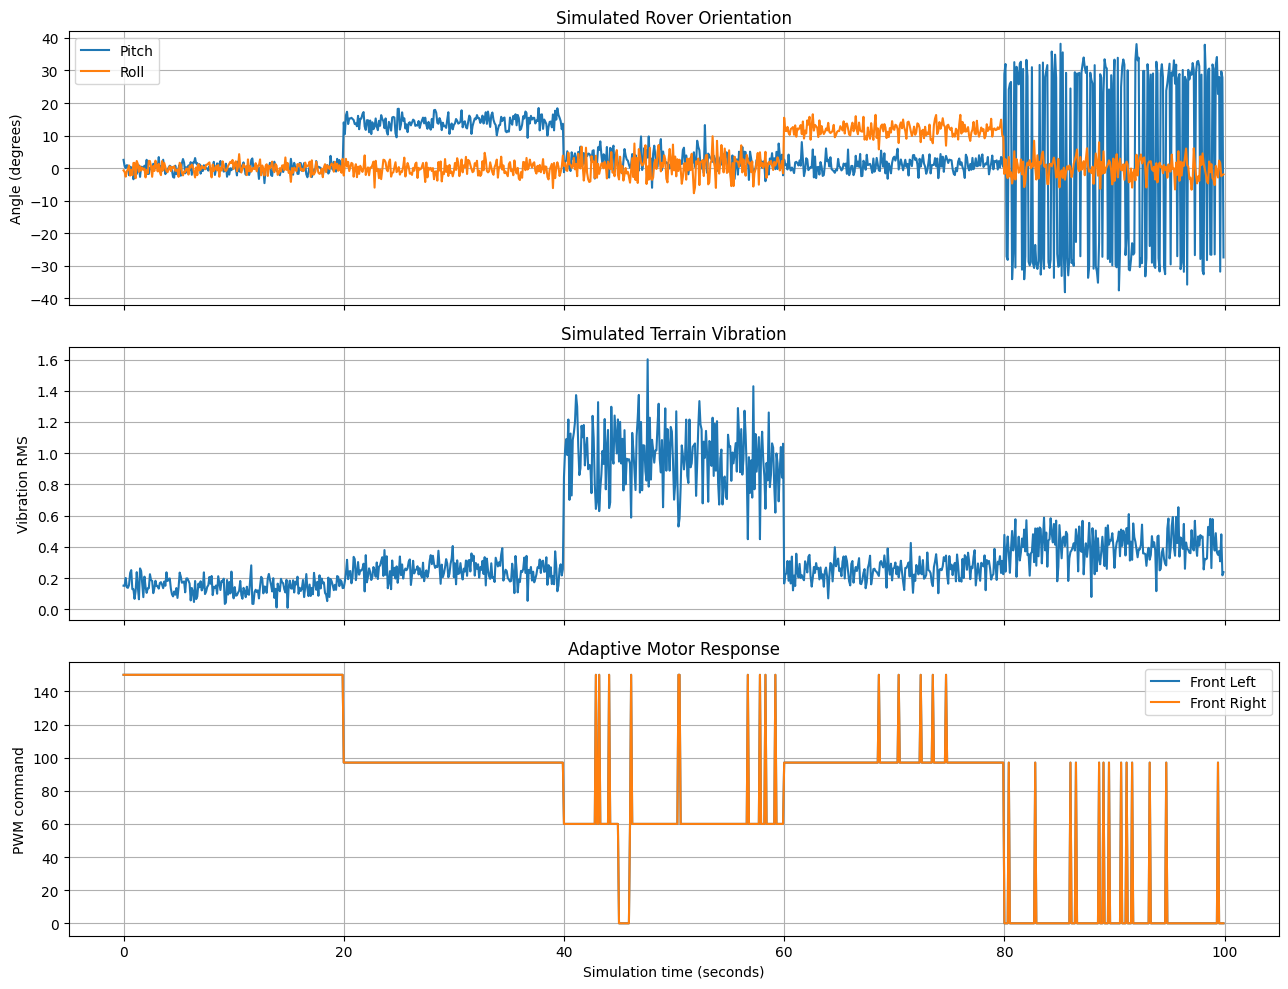

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

axes[0].plot(
    stream_df["time_s"],
    stream_df["pitch"],
    label="Pitch"
)
axes[0].plot(
    stream_df["time_s"],
    stream_df["roll"],
    label="Roll"
)
axes[0].set_ylabel("Angle (degrees)")
axes[0].set_title("Simulated Rover Orientation")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    stream_df["time_s"],
    stream_df["vibration_rms"]
)
axes[1].set_ylabel("Vibration RMS")
axes[1].set_title("Simulated Terrain Vibration")
axes[1].grid(True)

axes[2].plot(
    stream_df["time_s"],
    stream_df["front_left"],
    label="Front Left"
)
axes[2].plot(
    stream_df["time_s"],
    stream_df["front_right"],
    label="Front Right"
)
axes[2].set_ylabel("PWM command")
axes[2].set_xlabel("Simulation time (seconds)")
axes[2].set_title("Adaptive Motor Response")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
test_cases = [
    ("Flat", 0, 0, 0.15),
    ("Slope", 14, 0, 0.25),
    ("Rough", 2, 1, 1.0),
    ("Side_Slope", 1, 12, 0.25),
    ("High_Tilt", 30, 0, 0.4)
]

print("TERRAIN CONTROL TESTS")
print("-" * 65)

for name, pitch, roll, vibration in test_cases:

    detected = detect_terrain(pitch, roll, vibration)
    commands = adaptive_motor_control(detected)

    print(f"\nActual condition: {name}")
    print(f"Detected condition: {detected}")
    print(f"Motor commands: {commands}")

    if detected == "High_Tilt":
        assert all(speed == 0 for speed in commands.values())
        print("Safety test: PASS - zero motor commands")

# Verify the simulated sensor-fault response
fault_rows = stream_df[~stream_df["sensor_ok"]]

assert (
    fault_rows[["front_left", "front_right",
                "rear_left", "rear_right"]] == 0
).all().all()

print("\nSensor-fault test: PASS - zero motor commands")

TERRAIN CONTROL TESTS
-----------------------------------------------------------------

Actual condition: Flat
Detected condition: Flat
Motor commands: {'front_left': 150, 'front_right': 150, 'rear_left': 150, 'rear_right': 150}

Actual condition: Slope
Detected condition: Slope
Motor commands: {'front_left': 97, 'front_right': 97, 'rear_left': 97, 'rear_right': 97}

Actual condition: Rough
Detected condition: Rough
Motor commands: {'front_left': 60, 'front_right': 60, 'rear_left': 60, 'rear_right': 60}

Actual condition: Side_Slope
Detected condition: Side_Slope
Motor commands: {'front_left': 97, 'front_right': 97, 'rear_left': 97, 'rear_right': 97}

Actual condition: High_Tilt
Detected condition: High_Tilt
Motor commands: {'front_left': 0, 'front_right': 0, 'rear_left': 0, 'rear_right': 0}
Safety test: PASS - zero motor commands

Sensor-fault test: PASS - zero motor commands


Terrain accuracy: 97.07 %

Detailed classification report:
              precision    recall  f1-score   support

        Flat       0.93      1.00      0.96       200
   High_Tilt       1.00      0.94      0.97       200
       Rough       1.00      0.95      0.97       190
  Side_Slope       1.00      0.97      0.98       200
       Slope       0.93      1.00      0.97       200

    accuracy                           0.97       990
   macro avg       0.97      0.97      0.97       990
weighted avg       0.97      0.97      0.97       990



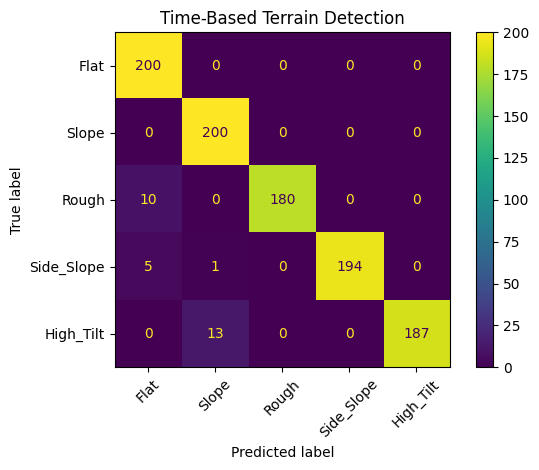

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

valid_df = stream_df[stream_df["sensor_ok"]]

y_true = valid_df["actual_terrain"]
y_pred = valid_df["predicted_terrain"]

print("Terrain accuracy:",
      round(accuracy_score(y_true, y_pred) * 100, 2), "%")

print("\nDetailed classification report:")
print(classification_report(y_true, y_pred, zero_division=0))

labels = [
    "Flat", "Slope", "Rough", "Side_Slope", "High_Tilt"
]

cm = confusion_matrix(y_true, y_pred, labels=labels)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(xticks_rotation=45)

plt.title("Time-Based Terrain Detection")
plt.tight_layout()
plt.show()

In [ ]:
output_file = "silver_rover_time_simulation.csv"

stream_df.to_csv(output_file, index=False)

from google.colab import files
files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

def adaptive_motor_control_v2(
    terrain,
    steering=0,
    base_speed=150
):
    """
    steering: -50 to +50
    Positive steering means turning right.
    Motor commands are simulated PWM values from 0 to 255.
    """

    base_speed = max(0, min(255, int(base_speed)))
    steering = max(-50, min(50, float(steering)))

    # Stop for unsafe tilt or unknown/fault conditions
    if terrain in ["High_Tilt", "Sensor_Fault", "Unknown"]:
        return {
            "front_left": 0,
            "front_right": 0,
            "rear_left": 0,
            "rear_right": 0
        }

    # Terrain-based speed limits
    speed_factors = {
        "Flat": 1.00,
        "Slope": 0.65,
        "Side_Slope": 0.65,
        "Rough": 0.40
    }

    factor = speed_factors.get(terrain, 0.0)

    # Differential steering:
    # Positive steering -> left wheels faster than right wheels
    left_speed = (base_speed + steering) * factor
    right_speed = (base_speed - steering) * factor

    # Keep commands in the valid PWM range
    left_speed = int(max(0, min(255, left_speed)))
    right_speed = int(max(0, min(255, right_speed)))

    return {
        "front_left": left_speed,
        "front_right": right_speed,
        "rear_left": left_speed,
        "rear_right": right_speed
    }


# Test the controller
for terrain in ["Flat", "Slope", "Rough", "High_Tilt"]:
    print(f"\nTerrain: {terrain}")

    print(
        "Straight:",
        adaptive_motor_control_v2(terrain, steering=0)
    )

    print(
        "Turning:",
        adaptive_motor_control_v2(terrain, steering=30)
    )



Terrain: Flat
Straight: {'front_left': 150, 'front_right': 150, 'rear_left': 150, 'rear_right': 150}
Turning: {'front_left': 180, 'front_right': 120, 'rear_left': 180, 'rear_right': 120}

Terrain: Slope
Straight: {'front_left': 97, 'front_right': 97, 'rear_left': 97, 'rear_right': 97}
Turning: {'front_left': 117, 'front_right': 78, 'rear_left': 117, 'rear_right': 78}

Terrain: Rough
Straight: {'front_left': 60, 'front_right': 60, 'rear_left': 60, 'rear_right': 60}
Turning: {'front_left': 72, 'front_right': 48, 'rear_left': 72, 'rear_right': 48}

Terrain: High_Tilt
Straight: {'front_left': 0, 'front_right': 0, 'rear_left': 0, 'rear_right': 0}
Turning: {'front_left': 0, 'front_right': 0, 'rear_left': 0, 'rear_right': 0}


In [ ]:

# Make a copy so your previous simulation remains unchanged
control_df = stream_df.copy()

# Simulated steering input, ranging approximately from -35 to +35
control_df["steering"] = (
    35 * np.sin(2 * np.pi * control_df["time_s"] / 12)
)

motor_rows = []

for _, row in control_df.iterrows():

    # Treat an unavailable sensor as a fault
    if not row["sensor_ok"]:
        terrain = "Sensor_Fault"
    else:
        terrain = row["predicted_terrain"]

    commands = adaptive_motor_control_v2(
        terrain=terrain,
        steering=row["steering"],
        base_speed=150
    )

    motor_rows.append(commands)

motor_df_v2 = pd.DataFrame(motor_rows, index=control_df.index)

control_df[
    ["front_left", "front_right", "rear_left", "rear_right"]
] = motor_df_v2[
    ["front_left", "front_right", "rear_left", "rear_right"]
]

print("Steering-aware simulation completed!")
display(
    control_df[
        [
            "time_s", "predicted_terrain", "steering",
            "front_left", "front_right",
            "rear_left", "rear_right"
        ]
    ].head(10)
)


Steering-aware simulation completed!


,time_s,predicted_terrain,steering,front_left,front_right,rear_left,rear_right
0,0.0,Flat,0.000000,150,150,150,150
1,0.1,Flat,1.831758,151,148,151,148
2,0.2,Flat,3.658496,153,146,153,146
3,0.3,Flat,5.475206,155,144,155,144
4,0.4,Flat,7.276909,157,142,157,142
5,0.5,Flat,9.058667,159,140,159,140
6,0.6,Flat,10.815595,160,139,160,139
7,0.7,Flat,12.542878,162,137,162,137
8,0.8,Flat,14.235783,164,135,164,135
9,0.9,Flat,15.889667,165,134,165,134


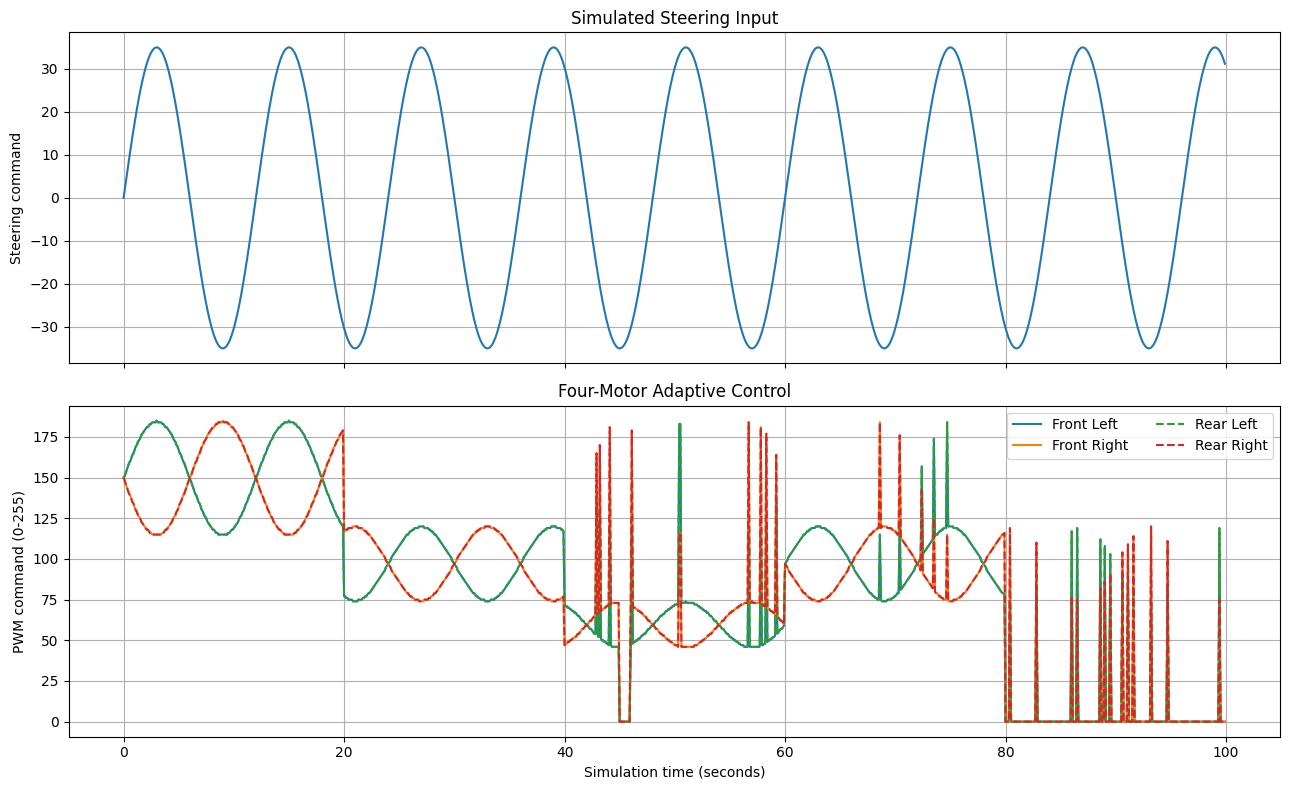

In [ ]:

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

axes[0].plot(
    control_df["time_s"],
    control_df["steering"]
)
axes[0].set_ylabel("Steering command")
axes[0].set_title("Simulated Steering Input")
axes[0].grid(True)

axes[1].plot(
    control_df["time_s"],
    control_df["front_left"],
    label="Front Left"
)
axes[1].plot(
    control_df["time_s"],
    control_df["front_right"],
    label="Front Right"
)
axes[1].plot(
    control_df["time_s"],
    control_df["rear_left"],
    linestyle="--",
    label="Rear Left"
)
axes[1].plot(
    control_df["time_s"],
    control_df["rear_right"],
    linestyle="--",
    label="Rear Right"
)

axes[1].set_xlabel("Simulation time (seconds)")
axes[1].set_ylabel("PWM command (0-255)")
axes[1].set_title("Four-Motor Adaptive Control")
axes[1].legend(ncol=2)
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [ ]:

# 1. Steering should create different left/right commands
straight = adaptive_motor_control_v2("Flat", steering=0)
turning = adaptive_motor_control_v2("Flat", steering=30)

assert straight["front_left"] == straight["front_right"]
assert turning["front_left"] > turning["front_right"]

# 2. Rough terrain should reduce the straight-line command
flat = adaptive_motor_control_v2("Flat", steering=0)
rough = adaptive_motor_control_v2("Rough", steering=0)

assert rough["front_left"] < flat["front_left"]

# 3. High tilt must produce zero commands
unsafe = adaptive_motor_control_v2("High_Tilt", steering=20)

assert all(value == 0 for value in unsafe.values())

# 4. Sensor fault must produce zero commands
fault = adaptive_motor_control_v2("Sensor_Fault", steering=20)

assert all(value == 0 for value in fault.values())

# 5. All commands must be between 0 and 255
motor_columns = [
    "front_left", "front_right",
    "rear_left", "rear_right"
]

assert control_df[motor_columns].ge(0).all().all()
assert control_df[motor_columns].le(255).all().all()

print("PASS: Steering control")
print("PASS: Rough-terrain speed reduction")
print("PASS: High-tilt stop command")
print("PASS: Sensor-fault stop command")
print("PASS: PWM command range")


PASS: Steering control
PASS: Rough-terrain speed reduction
PASS: High-tilt stop command
PASS: Sensor-fault stop command
PASS: PWM command range


In [ ]:

import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

# Dashboard controls
time_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=len(control_df) - 1,
    step=1,
    description="Sample:",
    continuous_update=False,
    layout=widgets.Layout(width="80%")
)

steering_slider = widgets.IntSlider(
    value=0,
    min=-50,
    max=50,
    step=5,
    description="Steering:",
    continuous_update=False
)

base_speed_slider = widgets.IntSlider(
    value=150,
    min=0,
    max=255,
    step=5,
    description="Base PWM:",
    continuous_update=False
)

dashboard_output = widgets.Output()

def update_dashboard(change=None):

    with dashboard_output:
        clear_output(wait=True)

        idx = time_slider.value
        row = control_df.iloc[idx]

        if not row["sensor_ok"]:
            terrain = "Sensor_Fault"
        else:
            terrain = row["predicted_terrain"]

        commands = adaptive_motor_control_v2(
            terrain,
            steering=steering_slider.value,
            base_speed=base_speed_slider.value
        )

        print("SILVER ROVER - SIMULATED MONITORING")
        print("=" * 42)
        print(f"Simulation time: {row['time_s']:.1f} seconds")
        print(f"Sensor status: {'OK' if row['sensor_ok'] else 'FAULT'}")
        print(f"Detected terrain: {terrain}")
        print(f"Pitch: {row['pitch']:.2f} degrees")
        print(f"Roll: {row['roll']:.2f} degrees")
        print(f"Vibration RMS: {row['vibration_rms']:.3f}")
        print(f"Steering input: {steering_slider.value}")
        print(f"Base PWM: {base_speed_slider.value}")

        if terrain in ["High_Tilt", "Sensor_Fault"]:
            print("SAFETY STATUS: STOP COMMAND")
        else:
            print("SAFETY STATUS: NORMAL SIMULATED CONTROL")

        print("\nFour motor commands:")
        for motor, pwm in commands.items():
            print(f"{motor:15s}: {pwm}")

        # Plot sensor history up to the selected sample
        history = control_df.iloc[:idx + 1]

        fig, axes = plt.subplots(2, 1, figsize=(10, 6))

        axes[0].plot(history["time_s"], history["pitch"], label="Pitch")
        axes[0].plot(history["time_s"], history["roll"], label="Roll")
        axes[0].set_ylabel("Angle (degrees)")
        axes[0].set_title("Rover Orientation History")
        axes[0].legend()
        axes[0].grid(True)

        axes[1].plot(
            history["time_s"],
            history["vibration_rms"]
        )
        axes[1].set_xlabel("Time (seconds)")
        axes[1].set_ylabel("Vibration RMS")
        axes[1].set_title("Terrain Vibration History")
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()
        plt.close(fig)

for widget in [time_slider, steering_slider, base_speed_slider]:
    widget.observe(update_dashboard, names="value")

display(widgets.VBox([
    time_slider,
    steering_slider,
    base_speed_slider,
    dashboard_output
]))

update_dashboard()
